<a href="https://colab.research.google.com/github/msanaullahchaudhary/kisaan-ai/blob/main/02_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf
print('TensorFlow', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!cp /content/drive/MyDrive/KisaanAI/data/raw.zip /content/
!unzip -q /content/raw.zip -d /content/
!ls /content/raw

plantdoc  plantvillage


In [3]:
import os
import pandas as pd
from PIL import Image

df = pd.read_csv('/content/drive/MyDrive/KisaanAI/data/splits.csv')

for path, cls, split in df.itertuples(index=False):
    folder = os.path.join('/content/splits', split, cls)
    os.makedirs(folder, exist_ok=True)
    new_name = path.replace('/', '_').rsplit('.', 1)[0] + '.jpg'
    with Image.open(os.path.join('/content/raw', path)) as im:
        im = im.convert('RGB')
        im.thumbnail((512, 512))
        im.save(os.path.join(folder, new_name), quality=92)

print(df['split'].value_counts())

split
lab_train      10547
lab_test        2261
lab_val         2258
field_train      550
field_val         98
field_test        68
Name: count, dtype: int64


In [4]:
import keras

CLASSES = ['Early_blight', 'Late_blight', 'Septoria_leaf_spot', 'Bacterial_spot',
           'Leaf_mold', 'Yellow_Leaf_Curl_Virus', 'Mosaic_virus', 'Healthy']
IMG_SIZE = 224
BATCH = 32

def load(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        f'/content/splits/{split}',
        class_names=CLASSES,
        label_mode='int',
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH,
        shuffle=shuffle,
        seed=42)

lab_train = load('lab_train', True)
lab_val = load('lab_val', False)

for images, labels in lab_train.take(1):
    print(images.shape, labels[:10].numpy())

Found 10547 files belonging to 8 classes.
Found 2258 files belonging to 8 classes.
(32, 224, 224, 3) [1 3 3 3 5 0 5 3 6 5]


In [5]:
import numpy as np

augment = keras.Sequential([
    keras.layers.RandomFlip('horizontal_and_vertical'),
    keras.layers.RandomRotation(0.15),
    keras.layers.RandomZoom((-0.2, 0.1)),
    keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    keras.layers.RandomContrast(0.2),
])

train_ds = lab_train.map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y)).prefetch(tf.data.AUTOTUNE)
val_ds = lab_val.prefetch(tf.data.AUTOTUNE)

counts = np.array([len(os.listdir(f'/content/splits/lab_train/{c}')) for c in CLASSES])
class_weight = {i: counts.sum() / (len(CLASSES) * counts[i]) for i in range(len(CLASSES))}
print(counts)
print({CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

[ 700 1331 1240 1489  666 3750  261 1110]
{'Early_blight': np.float64(1.88), 'Late_blight': np.float64(0.99), 'Septoria_leaf_spot': np.float64(1.06), 'Bacterial_spot': np.float64(0.89), 'Leaf_mold': np.float64(1.98), 'Yellow_Leaf_Curl_Virus': np.float64(0.35), 'Mosaic_virus': np.float64(5.05), 'Healthy': np.float64(1.19)}


In [6]:
base = keras.applications.MobileNetV3Large(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet',
    include_preprocessing=True)
base.trainable = False

x = keras.layers.GlobalAveragePooling2D(name='gap')(base.output)
x = keras.layers.Dropout(0.3, name='dropout')(x)
logits = keras.layers.Dense(len(CLASSES), name='logits')(x)
outputs = keras.layers.Activation('softmax', name='predictions')(logits)
model = keras.Model(base.input, outputs)

print('Total layers:', len(model.layers))
print('Trainable numbers:', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total layers: 191
Trainable numbers: 7688


In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

MODELS = '/content/drive/MyDrive/KisaanAI/models'
os.makedirs(MODELS, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage1.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weight,
    callbacks=callbacks)

Epoch 1/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 173s 469ms/step - accuracy: 0.6895 - loss: 1.0194 - val_accuracy: 0.8632 - val_loss: 0.4638
Epoch 2/8
330/330 ━━━━━━━━━━━━━━━━━━━━ 137s 416ms/step - accuracy: 0.8641 - loss: 0.4881 - val_accuracy: 0.8964 - val_loss: 0.3441
Epoch 3/8
 20/330 ━━━━━━━━━━━━━━━━━━━━ 2:15 437ms/step - accuracy: 0.8854 - loss: 0.4307

KeyboardInterrupt: 

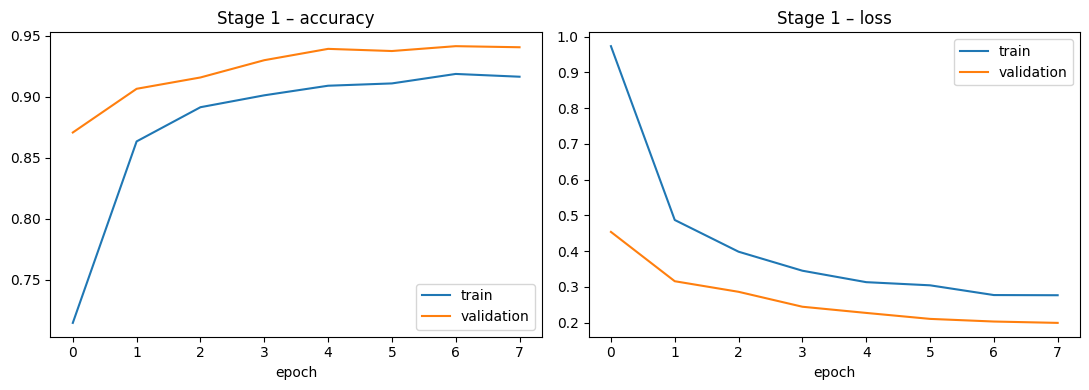

In [ ]:
import matplotlib.pyplot as plt

h = history1.history
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h['accuracy'], label='train')
ax[0].plot(h['val_accuracy'], label='validation')
ax[0].set_title('Stage 1 – accuracy'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h['loss'], label='train')
ax[1].plot(h['val_loss'], label='validation')
ax[1].set_title('Stage 1 – loss'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(f'{MODELS}/stage1_curves.png', dpi=150)
plt.show()

In [ ]:
# Stage 2: let the top 40% of MobileNetV3 learn too
base.trainable = True
n = len(base.layers)
cut = int(n * 0.6)   # bottom 60% stays frozen

for i, layer in enumerate(base.layers):
    if i < cut or isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

print('Base layers that will learn:', sum(l.trainable for l in base.layers), 'of', n)

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks2 = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage2.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
]

history2 = model.fit(train_ds, validation_data=val_ds, epochs=12,
                     class_weight=class_weight, callbacks=callbacks2)

Base layers that will learn: 60 of 187
Epoch 1/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 203s 539ms/step - accuracy: 0.9486 - loss: 0.1764 - val_accuracy: 0.9632 - val_loss: 0.1024 - learning_rate: 1.0000e-04
Epoch 2/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 150s 453ms/step - accuracy: 0.9716 - loss: 0.0887 - val_accuracy: 0.9721 - val_loss: 0.0965 - learning_rate: 1.0000e-04
Epoch 3/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 149s 452ms/step - accuracy: 0.9830 - loss: 0.0523 - val_accuracy: 0.9810 - val_loss: 0.0538 - learning_rate: 1.0000e-04
Epoch 4/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 150s 453ms/step - accuracy: 0.9840 - loss: 0.0479 - val_accuracy: 0.9836 - val_loss: 0.0451 - learning_rate: 1.0000e-04
Epoch 5/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 149s 452ms/step - accuracy: 0.9911 - loss: 0.0257 - val_accuracy: 0.9863 - val_loss: 0.0408 - learning_rate: 1.0000e-04
Epoch 6/12
330/330 ━━━━━━━━━━━━━━━━━━━━ 147s 445ms/step - accuracy: 0.9905 - loss: 0.0327 - val_accuracy: 0.9845 - val_loss: 0.0432 - learning_rate: 1.0000e-04
E

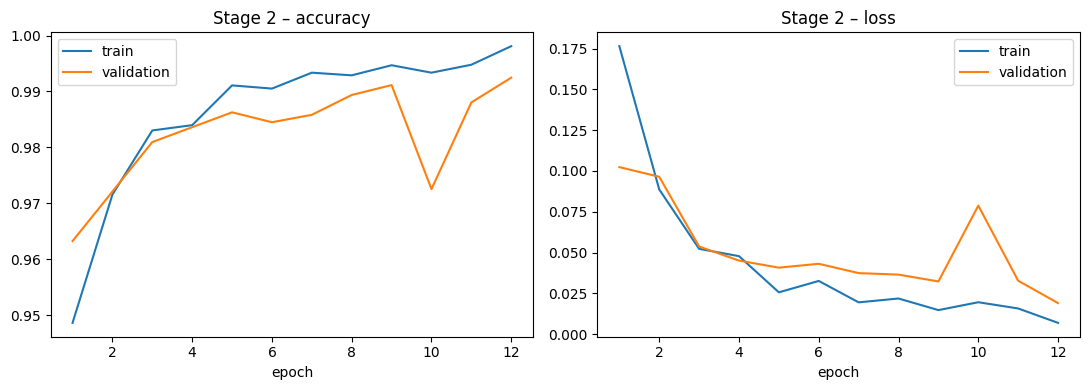

In [ ]:
def plot_history(history, title, filename):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for i, metric in enumerate(['accuracy', 'loss']):
        epochs = range(1, len(h[metric]) + 1)
        ax[i].plot(epochs, h[metric], label='train')
        ax[i].plot(epochs, h['val_' + metric], label='validation')
        ax[i].set_title(f'{title} – {metric}')
        ax[i].set_xlabel('epoch')
        ax[i].legend()
    plt.tight_layout()
    plt.savefig(f'{MODELS}/{filename}', dpi=150)
    plt.show()

plot_history(history2, 'Stage 2', 'stage2_curves.png')

In [ ]:
lab_test = load('lab_test', False)
field_test = load('field_test', False)

_, lab_acc = model.evaluate(lab_test, verbose=0)
_, field_acc = model.evaluate(field_test, verbose=0)
print(f'After stage 2  ->  lab test: {lab_acc:.1%}   field test: {field_acc:.1%}')

Found 2261 files belonging to 8 classes.
Found 68 files belonging to 8 classes.
After stage 2  ->  lab test: 99.1%   field test: 27.9%


In [ ]:
# Stage 3: field photos + the same number of lab photos
field_train = load('field_train', True)
field_val = load('field_val', False)

n_field = sum(len(os.listdir(f'/content/splits/field_train/{c}')) for c in CLASSES)
print('Field training photos:', n_field)

lab_sample = lab_train.unbatch().take(n_field)
mixed = field_train.unbatch().concatenate(lab_sample).shuffle(1200, seed=42).batch(BATCH)
mixed_ds = mixed.map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y)).prefetch(tf.data.AUTOTUNE)
field_val_ds = field_val.prefetch(tf.data.AUTOTUNE)

field_counts = np.array([len(os.listdir(f'/content/splits/field_train/{c}')) for c in CLASSES])
field_weight = {i: field_counts.sum() / (len(CLASSES) * field_counts[i]) for i in range(len(CLASSES))}

model.compile(optimizer=keras.optimizers.Adam(2e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks3 = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage3.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
]

history3 = model.fit(mixed_ds, validation_data=field_val_ds, epochs=15,
                     class_weight=field_weight, callbacks=callbacks3)

Found 550 files belonging to 8 classes.
Found 98 files belonging to 8 classes.
Field training photos: 550
Epoch 1/15
     35/Unknown 50s 832ms/step - accuracy: 0.6309 - loss: 4.2253

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.6355 - loss: 3.8456 - val_accuracy: 0.4082 - val_loss: 4.6748
Epoch 2/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 19s 495ms/step - accuracy: 0.6664 - loss: 1.9550 - val_accuracy: 0.4592 - val_loss: 3.0978
Epoch 3/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 20s 468ms/step - accuracy: 0.6645 - loss: 1.3289 - val_accuracy: 0.4796 - val_loss: 2.5650
Epoch 4/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 466ms/step - accuracy: 0.6882 - loss: 1.1696 - val_accuracy: 0.4898 - val_loss: 2.2032
Epoch 5/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 467ms/step - accuracy: 0.6818 - loss: 1.0135 - val_accuracy: 0.5000 - val_loss: 2.0271
Epoch 6/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 465ms/step - accuracy: 0.6927 - loss: 0.9483 - val_accuracy: 0.5102 - val_loss: 1.9300
Epoch 7/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 18s 470ms/step - accuracy: 0.6973 - loss: 0.8744 - val_accuracy: 0.5204 - val_loss: 1.8936
Epoch 8/15
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 444ms/step - accuracy: 0.7200 - loss: 0.8129 - val_accuracy: 0.5204 -

In [ ]:
import json
all_history = {}
for name, h in [('stage1', history1), ('stage2', history2), ('stage3a', history3)]:
    all_history[name] = {k: [float(v) for v in vals] for k, vals in h.history.items()}

with open(f'{MODELS}/history.json', 'w') as f:
    json.dump(all_history, f, indent=2)
print('Saved:', list(all_history))

Saved: ['stage1', 'stage2', 'stage3a']


In [8]:
MODELS = '/content/drive/MyDrive/KisaanAI/models'

# unlock the same layers as stage 2
base.trainable = True
cut = int(len(base.layers) * 0.6)
for i, layer in enumerate(base.layers):
    if i < cut or isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# test sets + stage 3 data (same as Cells 11 and 12)
lab_test = load('lab_test', False)
field_test = load('field_test', False)
field_train = load('field_train', True)
field_val = load('field_val', False)

n_field = sum(len(os.listdir(f'/content/splits/field_train/{c}')) for c in CLASSES)
lab_sample = lab_train.unbatch().take(n_field)
mixed = field_train.unbatch().concatenate(lab_sample).shuffle(1200, seed=42).batch(BATCH)
mixed_ds = mixed.map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y)).prefetch(tf.data.AUTOTUNE)
field_val_ds = field_val.prefetch(tf.data.AUTOTUNE)

field_counts = np.array([len(os.listdir(f'/content/splits/field_train/{c}')) for c in CLASSES])
field_weight = {i: field_counts.sum() / (len(CLASSES) * field_counts[i]) for i in range(len(CLASSES))}

Found 2261 files belonging to 8 classes.
Found 68 files belonging to 8 classes.
Found 550 files belonging to 8 classes.
Found 98 files belonging to 8 classes.


In [9]:
def check(name):
    model.load_weights(f'{MODELS}/{name}.keras')
    _, lab_acc = model.evaluate(lab_test, verbose=0)
    _, val_acc = model.evaluate(field_val_ds, verbose=0)
    _, field_acc = model.evaluate(field_test, verbose=0)
    print(f'{name:8s} ->  lab test: {lab_acc:.1%}   field val: {val_acc:.1%}   field test: {field_acc:.1%}')

check('stage2')
check('stage3')

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 76 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


stage2   ->  lab test: 99.1%   field val: 23.5%   field test: 27.9%
stage3   ->  lab test: 98.6%   field val: 52.0%   field test: 39.7%


In [ ]:
# Stage 3, try B: start again from stage 2, learning rate 1e-4
model.load_weights(f'{MODELS}/stage2.keras')
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks3b = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage3b.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True),
]
history3b = model.fit(mixed_ds, validation_data=field_val_ds, epochs=25,
                      class_weight=field_weight, callbacks=callbacks3b)

check('stage3b')

Epoch 1/25
     35/Unknown 58s 814ms/step - accuracy: 0.6549 - loss: 3.0184

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.6627 - loss: 1.9130 - val_accuracy: 0.5204 - val_loss: 1.7800
Epoch 2/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 17s 430ms/step - accuracy: 0.6991 - loss: 0.8497 - val_accuracy: 0.4796 - val_loss: 1.7127
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 16s 421ms/step - accuracy: 0.7482 - loss: 0.6822 - val_accuracy: 0.5102 - val_loss: 1.7088
Epoch 4/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 16s 421ms/step - accuracy: 0.7691 - loss: 0.6098 - val_accuracy: 0.4796 - val_loss: 1.7394
Epoch 5/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 16s 426ms/step - accuracy: 0.7964 - loss: 0.5210 - val_accuracy: 0.5102 - val_loss: 1.8248
Epoch 6/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 16s 420ms/step - accuracy: 0.8255 - loss: 0.4522 - val_accuracy: 0.4898 - val_loss: 2.0923
stage3b  ->  lab test: 96.4%   field val: 52.0%   field test: 41.2%


In [ ]:
model.load_weights(f'{MODELS}/stage3.keras')
model.save(f'{MODELS}/kisaan_final.keras')
check('kisaan_final')

kisaan_final ->  lab test: 98.6%   field val: 52.0%   field test: 39.7%


In [10]:
!rm -rf /content/splits/pk_train
!unzip -q -o /content/drive/MyDrive/KisaanAI/data/pk_train.zip -d /content/splits/
for c in CLASSES:
    os.makedirs(f'/content/splits/pk_train/{c}', exist_ok=True)

pd_counts = np.array([len(os.listdir(f'/content/splits/field_train/{c}')) for c in CLASSES])
pk_counts = np.array([len(os.listdir(f'/content/splits/pk_train/{c}')) for c in CLASSES])
field_total = pd_counts + pk_counts
lab_expected = counts * field_total.sum() / counts.sum()
mix_counts = field_total + lab_expected
mix_weight = {i: mix_counts.sum() / (len(CLASSES) * mix_counts[i]) for i in range(len(CLASSES))}

print('Field photos per class:', dict(zip(CLASSES, field_total.tolist())))
print('Weights:', {c: round(float(w), 2) for c, w in zip(CLASSES, mix_weight.values())})

Field photos per class: {'Early_blight': 843, 'Late_blight': 1022, 'Septoria_leaf_spot': 964, 'Bacterial_spot': 82, 'Leaf_mold': 1015, 'Yellow_Leaf_Curl_Virus': 702, 'Mosaic_virus': 37, 'Healthy': 669}
Weights: {'Early_blight': 1.11, 'Late_blight': 0.79, 'Septoria_leaf_spot': 0.84, 'Bacterial_spot': 1.6, 'Leaf_mold': 0.99, 'Yellow_Leaf_Curl_Virus': 0.51, 'Mosaic_virus': 7.89, 'Healthy': 1.08}


In [11]:
n_field = int(field_total.sum())
streams = [
    load('field_train', True).unbatch(),       # PlantDoc field photos
    load('pk_train', True).unbatch(),          # Pakistan field photos (clean)
    lab_train.unbatch().take(n_field),         # same number of lab photos
]
sizes = [int(pd_counts.sum()), int(pk_counts.sum()), n_field]
mixed3 = tf.data.Dataset.sample_from_datasets(streams, weights=[s / sum(sizes) for s in sizes], seed=42).batch(BATCH)
mixed3_ds = mixed3.map(lambda x, y: (tf.clip_by_value(augment(x, training=True), 0, 255), y)).prefetch(tf.data.AUTOTUNE)
print('Photos per epoch:', sum(sizes))

Found 550 files belonging to 8 classes.
Found 4784 files belonging to 8 classes.
Photos per epoch: 10668


In [12]:
model.load_weights(f'{MODELS}/stage2.keras')
model.compile(optimizer=keras.optimizers.Adam(2e-5),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks3c = [
    keras.callbacks.ModelCheckpoint(f'{MODELS}/stage3c.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True),
]
history3c = model.fit(mixed3_ds, validation_data=field_val_ds, epochs=15,
                      class_weight=mix_weight, callbacks=callbacks3c)

check('stage3c')

Epoch 1/15
    334/Unknown 185s 477ms/step - accuracy: 0.7191 - loss: 1.6798

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


334/334 ━━━━━━━━━━━━━━━━━━━━ 194s 504ms/step - accuracy: 0.7478 - loss: 1.1077 - val_accuracy: 0.5102 - val_loss: 2.2693
Epoch 2/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 143s 428ms/step - accuracy: 0.8214 - loss: 0.5518 - val_accuracy: 0.5408 - val_loss: 2.0591
Epoch 3/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 140s 419ms/step - accuracy: 0.8570 - loss: 0.4420 - val_accuracy: 0.5510 - val_loss: 1.8849
Epoch 4/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 143s 427ms/step - accuracy: 0.8840 - loss: 0.3660 - val_accuracy: 0.5612 - val_loss: 1.8627
Epoch 5/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 145s 432ms/step - accuracy: 0.8989 - loss: 0.3030 - val_accuracy: 0.5408 - val_loss: 1.8572
Epoch 6/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 143s 427ms/step - accuracy: 0.9144 - loss: 0.2502 - val_accuracy: 0.5204 - val_loss: 1.8718
Epoch 7/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 143s 429ms/step - accuracy: 0.9307 - loss: 0.2139 - val_accuracy: 0.5204 - val_loss: 1.9585
Epoch 8/15
334/334 ━━━━━━━━━━━━━━━━━━━━ 144s 431ms/step - accuracy: 0.9391 - loss: 0.18

In [13]:
model.save(f'{MODELS}/kisaan_final.keras')
check('kisaan_final')

import json
with open(f'{MODELS}/history.json') as f:
    all_history = json.load(f)
all_history['stage3c'] = {k: [float(v) for v in vals] for k, vals in history3c.history.items()}
with open(f'{MODELS}/history.json', 'w') as f:
    json.dump(all_history, f, indent=2)
print('Saved:', list(all_history))

kisaan_final ->  lab test: 99.0%   field val: 56.1%   field test: 44.1%
Saved: ['stage1', 'stage2', 'stage3a', 'stage3c']
